# Application 08 · Certify that a small neural network is robust

**Builds on:** [Lecture 08](../notebooks/08_automatic_differentiation.ipynb) (dual numbers), Lecture 07 (mean-value form, monotonicity), and Lecture 05 (Arb).

**Time:** about 60 minutes. **You will certify:** that a classifier gives the same answer for *every* input in a box around a test point, and find the largest such box.

A classifier is **robust at x with radius ε** if its decision does not change anywhere in the box |x′ − x|∞ ≤ ε. Attacks (searching for a bad x′) can only show that a network is *not* robust. Proving robustness needs a bound over the whole box, which is exactly an interval range enclosure. Formal verification of neural networks is a research area built on this idea.

## Google Colab setup — run this cell first

**Local Jupyter:** this cell skips Colab setup; use your installed course environment.

Use a **CPU Python runtime** (Python 3.12 or newer). Run the next cell and select
**vc_runtime.zip** from this edition when prompted. It loads the course helpers
and installs the arithmetic libraries. Repeat setup whenever you get a new runtime.
No Drive mounting or local Python installation is required.
Use this setup instead of the local installation and kernel-selection instructions
in the original course text.

Save a copy of this notebook in Drive, or download it after editing. Files created
by the project are under `/content/validated-course/build/certificates/`; download
those separately from Colab's Files panel. Runtime files are temporary.

Open other course notebooks using **File → Upload notebook**, choosing them from
the extracted course folder. Relative course links are intended for local Jupyter
and do not open sibling notebooks automatically in Colab.


In [1]:
try:
    import google.colab
except ImportError:
    print("Local Jupyter: using the installed course environment.")
else:
    import hashlib
    from pathlib import Path
    import subprocess
    import sys
    from google.colab import files

    if sys.version_info < (3, 12):
        raise RuntimeError("This course needs a Python 3.12 or newer Colab runtime.")

    # Upload the small companion file supplied with the Colab course edition.
    expected_hash = '833652c4a440f1c3a22bc6e68c59d533b41e6f9f1ff0b4af226f8fbee2244c1a'
    runtime_zip = Path("/content") / ("vc-course-" + expected_hash + ".zip")
    if not runtime_zip.exists():
        print("Select vc_runtime.zip from the extracted Colab course folder.")
        uploaded = files.upload()
        if len(uploaded) != 1:
            raise ValueError("Upload only vc_runtime.zip, then run this cell again.")
        archive_bytes = next(iter(uploaded.values()))
        if hashlib.sha256(archive_bytes).hexdigest() != expected_hash:
            raise ValueError("Wrong vc_runtime.zip: use the one supplied with this notebook.")
        runtime_zip.write_bytes(archive_bytes)

    if hashlib.sha256(runtime_zip.read_bytes()).hexdigest() != expected_hash:
        raise ValueError("The cached vc archive has changed; start a fresh runtime.")

    # Keep Colab's existing NumPy and plotting stack when they satisfy these bounds.
    # Install MPFR/Arb bindings, not the full local Jupyter environment.
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "--quiet",
        'numpy>=1.26', 'matplotlib>=3.8', 'gmpy2==2.3.1', 'python-flint==0.9.0', 'jupytext>=1.16'
    ])
    import gmpy2
    import flint
    if gmpy2.version() != "2.3.1" or flint.__version__ != "0.9.0":
        raise RuntimeError("Old arithmetic libraries are still loaded. Restart the session and run setup first.")

    if str(runtime_zip) not in sys.path:
        sys.path.insert(0, str(runtime_zip))

    import vc
    if not vc.__file__.startswith(str(runtime_zip) + "/"):
        raise RuntimeError("Another vc copy is already loaded. Start a fresh runtime.")

    # Preserve the relative output paths used by the project notebooks.
    import os
    working_folder = Path("/content/validated-course") / 'applications'
    working_folder.mkdir(parents=True, exist_ok=True)
    os.chdir(working_folder)
    print("Course helpers ready:", vc.__version__)

Local Jupyter: using the installed course environment.


In [2]:
from fractions import Fraction
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import display
from flint import arb, fmpq, ctx
from vc.intervals import RationalInterval as Interval
from vc.autodiff import Dual
from vc.arb_bridge import to_ball, from_ball

## 1 · The network

Two inputs, three hidden tanh units, one output score. The class is "positive" when the score is positive. The weights are small exact rationals; a trained network would have binary32 weights, which are also exact rationals.

Dual numbers in `vc` support `exp` but not `tanh`, so we use the identity

$$\tanh z = 1-\frac{2}{e^{2z}+1}.$$

The same Python function then works on floats (NumPy), on Arb balls, and on dual numbers whose parts are Arb balls.

In [3]:
HIDDEN_WEIGHTS = [(2, -1), (-1, 2), (1, 1)]
HIDDEN_BIAS = [fmpq(1, 2), fmpq(-1, 2), -1]
OUTPUT_WEIGHTS = [3, -2, -2]
OUTPUT_BIAS = fmpq(1, 2)

def tanh(z):
    return 1 - 2 / ((2 * z).exp() + 1)

def score(x, y):
    total = OUTPUT_BIAS
    for (w_x, w_y), bias, w_out in zip(HIDDEN_WEIGHTS, HIDDEN_BIAS, OUTPUT_WEIGHTS):
        hidden = tanh(w_x * x + w_y * y + bias)
        total = total + w_out * hidden
    return total

def score_float(x, y):
    """Plain binary64 evaluation for plots and attacks (no guarantee)."""
    total = float(OUTPUT_BIAS)
    for (w_x, w_y), bias, w_out in zip(HIDDEN_WEIGHTS, HIDDEN_BIAS, OUTPUT_WEIGHTS):
        total = total + w_out * np.tanh(w_x * x + w_y * y + float(bias))
    return total

## 2 · Three ways to enclose the score on a box

A box is a pair of rational intervals. Each method returns a rational interval containing the score at every point of the box.

1. **Natural:** evaluate `score` on Arb balls.
2. **Mean value:** with the box center c and a gradient enclosure G over the box,
   $$f(B)\subseteq f(c)+G_x\,(B_x-c_x)+G_y\,(B_y-c_y).$$
3. **Monotone corners:** if both gradient components have a fixed sign on the box, f is monotone in each coordinate. Its minimum and maximum are then attained at two known **corners**, and we only evaluate f at those two points.

The gradient enclosure comes from two forward passes with dual numbers, as in `jacobian2`.

In [4]:
PRECISION = 64

def natural(box):
    with ctx.workprec(PRECISION):
        x, y = to_ball(box[0]), to_ball(box[1])
        return from_ball(score(x, y))

def gradient(box):
    with ctx.workprec(PRECISION):
        x, y = to_ball(box[0]), to_ball(box[1])
        d_dx = score(Dual(x, arb(1)), Dual(y, arb(0))).derivative
        d_dy = score(Dual(x, arb(0)), Dual(y, arb(1))).derivative
        return from_ball(d_dx), from_ball(d_dy)

def mean_value(box):
    center = [Interval(side.midpoint()) for side in box]
    g_x, g_y = gradient(box)
    return natural(center) + g_x * (box[0] - center[0]) + g_y * (box[1] - center[1])

def sign(interval):
    if interval.lo > 0:
        return 1
    if interval.hi < 0:
        return -1
    return 0   # unknown sign: no monotonicity conclusion

def monotone_corners(box):
    g_x, g_y = gradient(box)
    s_x, s_y = sign(g_x), sign(g_y)
    if s_x == 0 or s_y == 0:
        return natural(box)          # fall back to a valid, cruder enclosure
    low_corner = (box[0].lo if s_x > 0 else box[0].hi, box[1].lo if s_y > 0 else box[1].hi)
    high_corner = (box[0].hi if s_x > 0 else box[0].lo, box[1].hi if s_y > 0 else box[1].lo)
    lowest = natural([Interval(low_corner[0]), Interval(low_corner[1])])
    highest = natural([Interval(high_corner[0]), Interval(high_corner[1])])
    return Interval(lowest.lo, highest.hi)

## 3 · The largest certified radius

A box is certified if the enclosure excludes 0. Larger boxes are harder, so we search for the largest certified ε by bisection. Bisection on ε is only a search strategy: each reported radius was checked by an actual certificate.

In [5]:
def box_around(point, radius):
    return [Interval(point[0] - radius, point[0] + radius),
            Interval(point[1] - radius, point[1] + radius)]

def is_certified(method, point, radius):
    enclosure = method(box_around(point, radius))
    return enclosure.lo > 0 or enclosure.hi < 0

def certified_radius(method, point, steps=16):
    good, bad = Fraction(0), Fraction(2)
    for _ in range(steps):
        trial = (good + bad) / 2
        if is_certified(method, point, trial):
            good = trial
        else:
            bad = trial
    return good

points = {"far": (Fraction(1, 2), Fraction(1, 4)),
          "near": (Fraction(-1, 5), Fraction(3, 10)),
          "very near": (Fraction(-3, 10), Fraction(3, 10))}
methods = {"natural": natural, "mean value": mean_value, "monotone corners": monotone_corners}

radii = {}
for label, point in points.items():
    radii[label] = {name: certified_radius(method, point) for name, method in methods.items()}
    row = "  ".join(f"{name}: {float(r):.4f}" for name, r in radii[label].items())
    print(f"{label:10s} score={score_float(*map(float, point)):+.3f}   {row}")

far        score=+4.459   natural: 0.3046  mean value: 0.1215  monotone corners: 0.3046
near       score=+0.758   natural: 0.0483  mean value: 0.0350  monotone corners: 0.0562
very near  score=+0.123   natural: 0.0085  mean value: 0.0086  monotone corners: 0.0097


**Reading the table.**

- The mean-value form is *worse* than natural evaluation on large boxes. tanh saturates, so the gradient bound over a big box is loose. This is Lecture 07's "centered forms can be worse" in a realistic setting.
- The monotone-corner test is never worse than natural evaluation (it falls back to it). Near the decision boundary, where the radii are small, it is the clear winner: the derivative signs are fixed on small boxes, and two point evaluations are almost exact.

## 4 · An attack gives the other side

The fast gradient sign method (FGSM) moves a distance ε in the direction −sign(∇f) (for a positive point), which is the worst corner if f were linear. If the score at that corner is negative, the box of radius ε contains a counterexample. We evaluate the corner score with Arb at the exact rational corner, so a counterexample found this way is **certified**, even though the search was heuristic.

Together: certified radius ≤ true robust radius ≤ attack radius.

In [6]:
def attack_radius(point, steps=16):
    g_x, g_y = gradient([Interval(point[0]), Interval(point[1])])
    direction = (-sign(g_x), -sign(g_y))      # decrease the (positive) score
    def corner_is_negative(radius):
        corner = [Interval(point[0] + radius * direction[0]), Interval(point[1] + radius * direction[1])]
        return natural(corner).hi < 0          # certified counterexample
    good, bad = Fraction(0), Fraction(2)       # bad: a counterexample radius
    for _ in range(steps):
        trial = (good + bad) / 2
        if corner_is_negative(trial):
            bad = trial
        else:
            good = trial
    return bad

for label, point in points.items():
    lower = radii[label]["monotone corners"]
    upper = attack_radius(point)
    print(f"{label:10s} robust radius in [{float(lower):.4f}, {float(upper):.4f}]")

far        robust radius in [0.3046, 0.3946]
near       robust radius in [0.0562, 0.0562]
very near  robust radius in [0.0097, 0.0097]


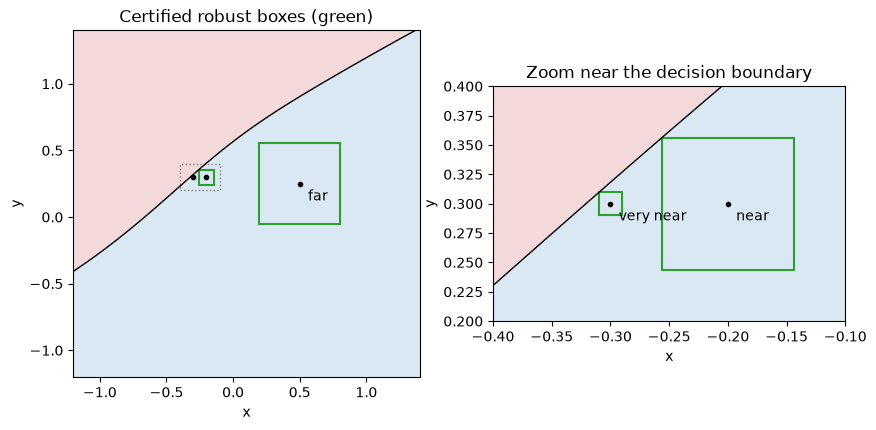

In [7]:
def draw(ax, xlim, ylim):
    gx = np.linspace(*xlim, 300)
    gy = np.linspace(*ylim, 300)
    X, Y = np.meshgrid(gx, gy)
    values = score_float(X, Y)
    ax.contourf(X, Y, values > 0, levels=[-0.5, 0.5, 1.5], colors=["#f3d9d9", "#d9e8f3"])
    ax.contour(X, Y, values, levels=[0], colors="black", linewidths=1)
    for label, point in points.items():
        r = float(radii[label]["monotone corners"])
        x0, y0 = float(point[0]), float(point[1])
        ax.add_patch(Rectangle((x0 - r, y0 - r), 2 * r, 2 * r, fill=False, color="tab:green", linewidth=1.5))
        ax.plot(x0, y0, "k.")
    ax.set(xlim=xlim, ylim=ylim, aspect="equal", xlabel="x", ylabel="y")

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
draw(axes[0], (-1.2, 1.4), (-1.2, 1.4))
axes[0].add_patch(Rectangle((-0.4, 0.2), 0.3, 0.2, fill=False, linestyle=":", color="gray"))
axes[0].annotate("far", (0.5, 0.25), textcoords="offset points", xytext=(6, -12))
axes[0].set_title("Certified robust boxes (green)")
draw(axes[1], (-0.4, -0.1), (0.2, 0.4))
for label in ["near", "very near"]:
    axes[1].annotate(label, tuple(float(c) for c in points[label]), textcoords="offset points", xytext=(6, -12))
axes[1].set_title("Zoom near the decision boundary")
plt.close(fig)
display(fig)

## 5 · Where it fails

The monotone test needs gradient enclosures that exclude zero. That fails if a partial derivative really vanishes in the box (a ridge of the score), or if the enclosure is simply too crude. On large boxes both happen, and the test falls back to natural evaluation.

In [8]:
ridge_box = box_around((Fraction(1, 2), Fraction(1, 4)), Fraction(3, 10))
g_x, g_y = gradient(ridge_box)
print("gradient enclosure on the box:", [float(g_x.lo), float(g_x.hi)], [float(g_y.lo), float(g_y.hi)])
print("monotone test applies:", sign(g_x) != 0 and sign(g_y) != 0)

gradient enclosure on the box: [-160.77330692537706, 215.9931844877394] [-140.53233114753033, 93.02500685181353]
monotone test applies: False


The remedy is the usual one: split the box and apply the test on each part (Exercise 1). Real verifiers combine exactly these tools (interval propagation, linear bounds from derivatives, and branching on input regions).

## Exercises

1. **Subdivision.** Write `split_method(method, k)` that splits a box into k×k sub-boxes and returns the hull of the enclosures. How close does `split_method(monotone_corners, 4)` get to the attack radius for the "far" point? What does it cost?
2. **Lipschitz radius.** From the gradient enclosure on a box B, compute L = max(|G_x|) + max(|G_y|). Prove that if f(c) > L·ε then the ε-box is certified. Compare the radius this gives with the table above.
3. **Wider network.** Add two more hidden units with weights of your choice. Which method degrades most, and why? (Think about how many times each input appears in the expression.)
4. **Binary32 weights.** Replace each weight w by `Fraction.from_float(float(numpy.float32(w + 0.001)))`. Explain why the certificate is about the *stored* network and not about the network "intended" by the training code.